# Импорт необходимых библиотек

In [1]:
import pandas as pd
import numpy as np
from dateutil import parser
import matplotlib.pylab as plt
import seaborn as sns
from operator import attrgetter

# Загрузка данных

In [2]:
orders = pd.read_csv('olist_orders_dataset.csv')
users = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')

# Анализ данных

## Пункт 1
Посмотрим на структуру данных и определим, какие статусы заказов будем учитывать для анализа retention.

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.groupby('order_status').order_id.nunique()

order_status
approved           2
canceled         625
created            5
delivered      96478
invoiced         314
processing       301
shipped         1107
unavailable      609
Name: order_id, dtype: int64

Для анализа retention мы будем учитывать только статусы заказов, которые означают успешное завершение покупки, такие как delivered.
Теперь мы можем рассчитать retention.

In [5]:
# Преобразование времени в datetime
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

In [6]:
# Создание столбца с годом и месяцем покупки
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

In [7]:
# Фильтрация только успешных заказов
successful_orders = orders[(orders['order_status'] == 'delivered')]

In [8]:
# Получение уникального id пользователя по заказу
successful_orders_transf = successful_orders.merge(users[['customer_id', 'customer_unique_id']],
                                                 on='customer_id',
                                                 how='left')

In [9]:
# Создаём копию данных, чтобы избежать изменений в исходном DataFrame
data_copy = successful_orders_transf.copy()

# Извлекаем день заказа
data_copy['order_period_day'] = data_copy['order_purchase_timestamp'].dt.to_period('D')

# Присваиваем когорты на основе даты первого действия для каждого пользователя
data_copy['cohort'] = data_copy.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
data_copy['cohort_day'] = data_copy.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('D')

# Рассчитываем номер периода в днях (месячные периоды, деля на 30)
data_copy['period_number_month'] = np.floor((data_copy.order_period_day - data_copy.cohort_day).apply(attrgetter('n')) / 30)


# Агрегируем данные по когортам и рассчитанному номеру периода (в месяцах)
df_cohort = data_copy.groupby(['cohort', 'period_number_month']).agg(n_customers=('customer_unique_id', 'nunique')).reset_index()

# Создаём сводную таблицу для когортного анализа
cohort_pivot = df_cohort.pivot_table(index='cohort', columns='period_number_month', values='n_customers')


# Рассчитываем размеры когорт (первый столбец сводной таблицы)
cohort_size = cohort_pivot.iloc[:, 0]

# Вычисляем коэффициенты удержания, деля на размер когорты
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)

In [10]:
cohort_pivot

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,...,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,1.0,1.0
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,NaN,4.0,1.0,1.0,2.0,2.0,NaN,NaN,...,4.0,3.0,2.0,NaN,2.0,2.0,2.0,1.0,NaN,NaN
2017-02,1628.0,2.0,3.0,6.0,4.0,2.0,4.0,1.0,2.0,4.0,...,6.0,1.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN,NaN
2017-03,2503.0,7.0,13.0,11.0,3.0,2.0,9.0,4.0,6.0,6.0,...,4.0,4.0,3.0,7.0,2.0,3.0,2.0,NaN,NaN,NaN
2017-04,2256.0,8.0,6.0,1.0,6.0,8.0,6.0,10.0,5.0,6.0,...,3.0,NaN,2.0,2.0,2.0,2.0,NaN,NaN,NaN,NaN
2017-05,3451.0,14.0,14.0,8.0,13.0,11.0,11.0,4.0,10.0,9.0,...,11.0,6.0,3.0,7.0,4.0,NaN,NaN,NaN,NaN,NaN
2017-06,3037.0,13.0,15.0,11.0,5.0,16.0,9.0,6.0,4.0,10.0,...,9.0,3.0,9.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
retention_matrix

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003817,NaN,NaN,0.003817,...,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,0.007634,0.003817,0.003817
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002789,NaN,0.005579,0.001395,0.001395,0.002789,0.002789,NaN,NaN,...,0.005579,0.004184,0.002789,NaN,0.002789,0.002789,0.002789,0.001395,NaN,NaN
2017-02,1.0,0.001229,0.001843,0.003686,0.002457,0.001229,0.002457,0.000614,0.001229,0.002457,...,0.003686,0.000614,0.001843,0.001229,0.000614,0.000614,0.001843,NaN,NaN,NaN
2017-03,1.0,0.002797,0.005194,0.004395,0.001199,0.000799,0.003596,0.001598,0.002397,0.002397,...,0.001598,0.001598,0.001199,0.002797,0.000799,0.001199,0.000799,NaN,NaN,NaN
2017-04,1.0,0.003546,0.002660,0.000443,0.002660,0.003546,0.002660,0.004433,0.002216,0.002660,...,0.001330,NaN,0.000887,0.000887,0.000887,0.000887,NaN,NaN,NaN,NaN
2017-05,1.0,0.004057,0.004057,0.002318,0.003767,0.003187,0.003187,0.001159,0.002898,0.002608,...,0.003187,0.001739,0.000869,0.002028,0.001159,NaN,NaN,NaN,NaN,NaN
2017-06,1.0,0.004281,0.004939,0.003622,0.001646,0.005268,0.002963,0.001976,0.001317,0.003293,...,0.002963,0.000988,0.002963,0.001317,NaN,NaN,NaN,NaN,NaN,NaN


Теперь рассчитаем усредненный retention за первый месяц по всем когортам.

In [12]:
# Усреднённый retention за первый месяц
average_retention_first_month = retention_matrix[1].median()
print(f'Медианный retention за первый месяц: {average_retention_first_month:.4f}')

Медианный retention за первый месяц: 0.0035


In [13]:
# Поиск когорты с самым высоким retention на третий месяц (кохорта с индексом 3)
highest_retention_third_month = retention_matrix[3].idxmax()
highest_retention_value = retention_matrix[3].max()

print(f'Когорта с самым высоким retention на третий месяц: {highest_retention_third_month}, значение: {highest_retention_value:.4f}%')

Когорта с самым высоким retention на третий месяц: 2017-01, значение: 0.0056%


# Пункт 2

Исходя из матрицы когортного анализа данный продукт имеет слабый product/market fit.


1. Привлечение новых клиентов: Когортный анализ показывает, что каждый месяц в продукт приходит значительное количество новых клиентов, с медианным значением в 4057 клиентов. Этот стабильный поток новых пользователей указывает на то, что маркетплейс способен привлекать интересующихся клиентов, которые готовы совершать покупки. Однако важно отметить, что наличие стабильного потока новых клиентов не всегда гарантирует долгосрочный успех бизнеса.

2. Проблемы удержания клиентов: Несмотря на привлекательность для новых пользователей, когортный анализ показывает, что лишь 0.3% клиентов (по медиане) остаются активными на первый месяц после первой покупки, а на второй месяц этот показатель значительно снижается до нуля. Это говорит о том, что большинство новых пользователей не находят достаточной ценности в продукте или услуге, чтобы продолжать использовать его. Высокий уровень оттока на ранних этапах взаимодействия с продуктом указывает на потенциальные проблемы с его качеством, функциональностью или соответствием ожиданиям клиентов.

3. Необходимость в улучшении ценностного предложения: Низкий уровень удержания клиентов может свидетельствовать о том, что маркетплейс не предоставляет достаточной ценности или уникальности по сравнению с конкурентами. Это может быть связано с недостаточной дифференциацией продукта, проблемами с качеством обслуживания или отсутствием необходимых функций и услуг.

В целом, текущие данные о retention указывают на слабый product/market fit для данного маркетплейса. Стабильный поток новых клиентов является положительным знаком, однако низкий уровень удержания сигнализирует о необходимости серьезных изменений в подходе к продукту и клиентскому обслуживанию.


# Пункт 3

1. **Рост продаж маркетплейса**

Метрика: Общий объем продаж (Gross Merchandise Volume, GMV)

Описание: Эта метрика отражает общий объем продаж через маркетплейс за определенный период. Она показывает, насколько успешно маркетплейс привлекает покупателей и генерирует доход.



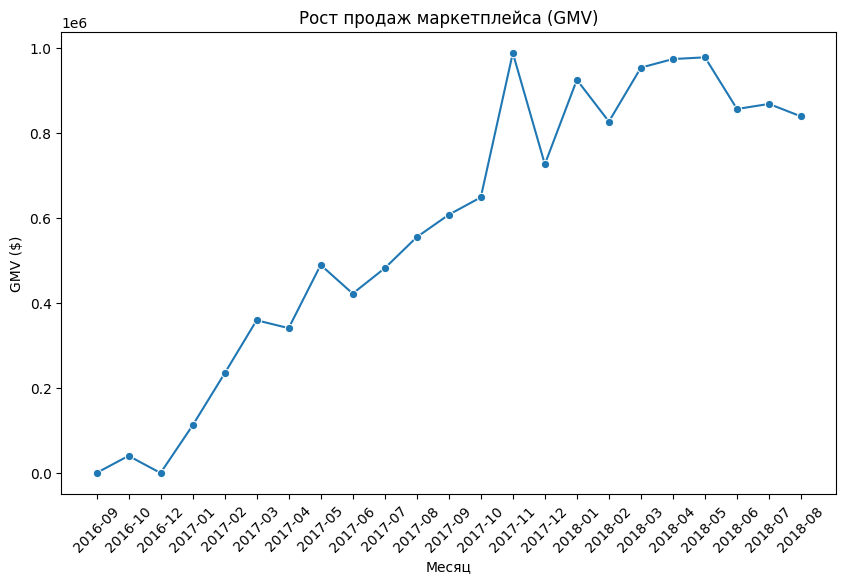

In [14]:
# Расчет GMV
gmv_data = successful_orders.merge(order_items[['order_id', 'price']], on='order_id')
monthly_gmv = gmv_data.groupby('order_month')['price'].sum().reset_index()
monthly_gmv['order_month'] = monthly_gmv['order_month'].astype(str)
monthly_gmv.columns = ['order_month', 'GMV']

plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_gmv, x='order_month', y='GMV', marker='o')
plt.title('Рост продаж маркетплейса (GMV)')
plt.xlabel('Месяц')
plt.ylabel('GMV ($)')
plt.xticks(rotation=45)

plt.show()

2. **Объем аудитории, которой продукт доставляет ценность**

Метрика: Количество платящих клиентов (Paying Users)

Описание: Эта метрика показывает количество уникальных пользователей, которые совершают хотя бы один заказ в продукте в течение месяца. Она помогает оценить, сколько клиентов на самом деле извлекают ценность из маркетплейса, то есть находят тот товар, который им нужен.

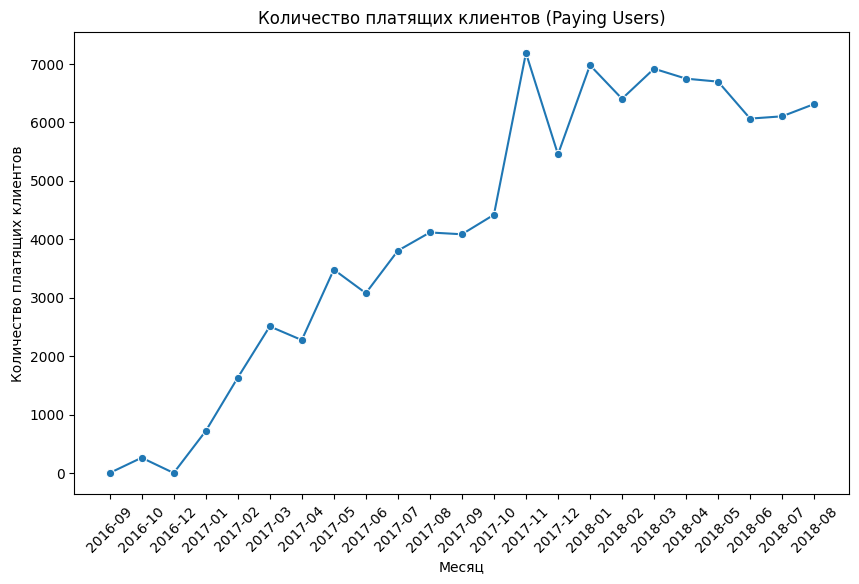

In [15]:
paying_users = successful_orders_transf.groupby(successful_orders_transf['order_month']).customer_unique_id.nunique().reset_index()
paying_users['order_month'] = paying_users['order_month'].astype(str)
paying_users.columns = ['order_month', 'paying_users']

plt.figure(figsize=(10, 6))
sns.lineplot(data=paying_users, x='order_month', y='paying_users', marker='o')
plt.title('Количество платящих клиентов (Paying Users)')
plt.xlabel('Месяц')
plt.ylabel('Количество платящих клиентов')
plt.xticks(rotation=45)

plt.show()



3. **Заинтересованность новых клиентов в продукте**

Метрика: Конверсия в первую покупку (Conversion to Paying User)

Описание: Эта метрика измеряет процент новых пользователей, которые совершают покупку после первого визита на сайт или в приложение. Она отражает, насколько эффективно маркетплейс привлекает и конвертирует новых клиентов.





4. **Вовлеченность клиента в продолжение использования продукта**

Метрика: Коэффициент удержания (Retention Rate)

Описание: Эта метрика показывает процент клиентов, которые продолжают использовать продукт после первого месяца. Она помогает понять, насколько хорошо продукт удерживает клиентов и удовлетворяет их потребности.

In [16]:
retention_matrix

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003817,NaN,NaN,0.003817,...,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,0.007634,0.003817,0.003817
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002789,NaN,0.005579,0.001395,0.001395,0.002789,0.002789,NaN,NaN,...,0.005579,0.004184,0.002789,NaN,0.002789,0.002789,0.002789,0.001395,NaN,NaN
2017-02,1.0,0.001229,0.001843,0.003686,0.002457,0.001229,0.002457,0.000614,0.001229,0.002457,...,0.003686,0.000614,0.001843,0.001229,0.000614,0.000614,0.001843,NaN,NaN,NaN
2017-03,1.0,0.002797,0.005194,0.004395,0.001199,0.000799,0.003596,0.001598,0.002397,0.002397,...,0.001598,0.001598,0.001199,0.002797,0.000799,0.001199,0.000799,NaN,NaN,NaN
2017-04,1.0,0.003546,0.002660,0.000443,0.002660,0.003546,0.002660,0.004433,0.002216,0.002660,...,0.001330,NaN,0.000887,0.000887,0.000887,0.000887,NaN,NaN,NaN,NaN
2017-05,1.0,0.004057,0.004057,0.002318,0.003767,0.003187,0.003187,0.001159,0.002898,0.002608,...,0.003187,0.001739,0.000869,0.002028,0.001159,NaN,NaN,NaN,NaN,NaN
2017-06,1.0,0.004281,0.004939,0.003622,0.001646,0.005268,0.002963,0.001976,0.001317,0.003293,...,0.002963,0.000988,0.002963,0.001317,NaN,NaN,NaN,NaN,NaN,NaN


5. **Денежное выражение вовлеченности клиента**

Метрика: ARPPU

Описание: Эта метрика отражает общую выручку, которую компания получает с одного клиента в среднем

In [17]:
# Объединяем с таблицей клиентов для получения customer_unique_id
order_all_info = gmv_data.merge(users[['customer_id', 'customer_unique_id']], on='customer_id')

monthly_revenue = order_all_info.groupby('order_month').agg(
    total_revenue=('price', 'sum'),
    paying_users=('customer_unique_id', 'nunique')).reset_index()

monthly_revenue['ARRPU'] = monthly_revenue['total_revenue'] / monthly_revenue['paying_users']

monthly_revenue[['order_month', 'total_revenue', 'paying_users', 'ARRPU']]

,order_month,total_revenue,paying_users,ARRPU
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,262,153.912634
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,718,155.708022
4,2017-02,234223.40,1630,143.695337
5,2017-03,359198.85,2508,143.221232
6,2017-04,340669.68,2274,149.810765
7,2017-05,489338.25,3479,140.654858
8,2017-06,421923.37,3076,137.166245
9,2017-07,481604.52,3802,126.671362


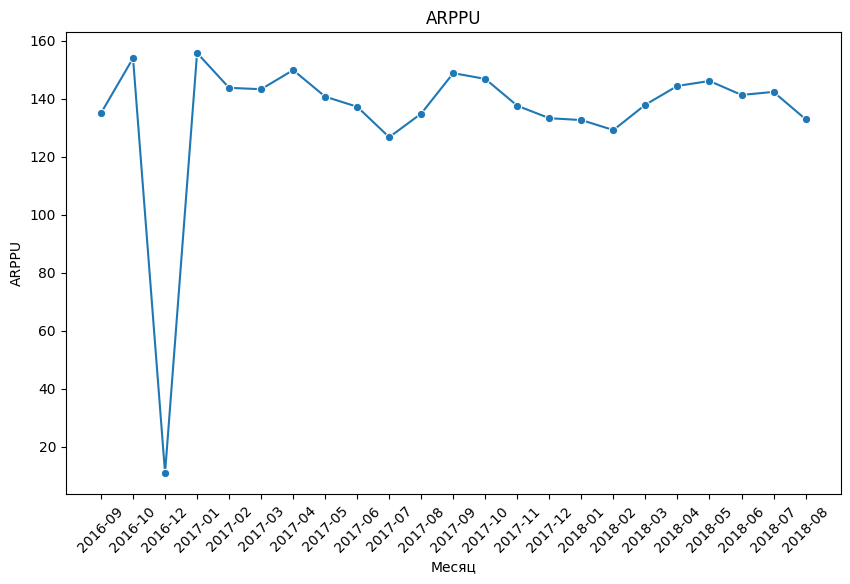

In [18]:
monthly_revenue['order_month'] = monthly_revenue['order_month'].astype(str)

plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_revenue, x='order_month', y='ARRPU', marker='o')
plt.title('ARPPU')
plt.xlabel('Месяц')
plt.ylabel('ARPPU')
plt.xticks(rotation=45)

plt.show()

# Пункт 4

**Гипотеза 1. Если исправим баг в системе процессинга заказов, то клиентам не придется сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится.**

Для расчета Impact по этой гипотезе можно посчитать количество заказов, который остались в статусе отмены. Заказом в статусе отмены будем считать статусы: canceled, unavailable

In [19]:
orders[orders.order_month >= '2017-06'].groupby('order_status').order_id.nunique()

order_status
canceled         499
created            5
delivered      85413
invoiced         240
processing       202
shipped          912
unavailable      475
Name: order_id, dtype: int64

In [20]:
count_canceled = orders[(orders.order_month >= '2017-06') &
                        (orders.order_status.isin(['canceled', 'unavailable']))].order_id.nunique()
print(f'Количество отмененных заказов: {count_canceled}')

Количество отмененных заказов: 974


**Гипотеза 2.
Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счет повторных заказов.**

Для расчета Impact по этой гипотезе можно посчитать количество заказов, которые были доставлены с опозданием. Конверсию в повторный заказ возьмем равной 0.0035.

In [21]:
# Преобразование времени в datetime
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])

In [22]:
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

In [23]:
# Создание столбца с годом и месяцем покупки
orders['order_delivery_day'] = orders['order_delivered_customer_date'].dt.to_period('D')
orders['order_estimated_day'] = orders['order_estimated_delivery_date'].dt.to_period('D')

In [24]:
count_delayed = orders[(orders.order_month >= '2017-06') & (orders.order_delivery_day > orders.order_estimated_day)
                      & (orders.order_status.isin(['delivered']))].order_id.nunique()

In [25]:
print(f'Количество задержанных заказов: {count_delayed}')

Количество задержанных заказов: 6087


In [26]:
print(f'Возможное количество повторных заказов: {count_delayed*0.0035}')

Возможное количество повторных заказов: 21.3045


**Гипотеза 3.
Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при выполнении заказа, вследствие чего  количество заказов увеличится за счет повторных заказов.**

Для расчета Impact по этой гипотезе можно посчитать количество заказов, где клиент сделал только единичный заказ. Конверсию в повторный заказ возьмем равной 0.0035.

In [27]:
# Подсчитываем количество заказов для каждого клиента
customer_order_counts = successful_orders_transf[(successful_orders_transf.order_month >= '2017-06')].groupby('customer_unique_id').order_id.nunique().reset_index()

# Определяем количество клиентов, которые сделали только один заказ
single_order_customers_count = (customer_order_counts == 1).order_id.sum()

In [28]:
customer_order_counts.groupby('order_id').nunique('customer_unique_id')

,customer_unique_id
order_id,
1,80558
2,2137
3,129
4,23
5,9
6,2
7,3
9,1
15,1


In [29]:
print(f'Количество задержанных заказов: {single_order_customers_count}')

Количество задержанных заказов: 80558


In [30]:
print(f'Возможное количество повторных заказов: {single_order_customers_count*0.0035}')

Возможное количество повторных заказов: 281.95300000000003


При сравнении по фреймворку ICE из 3 гипотез выигрывает гипотеза 1.

# Пункт 5

Для проверки гипотезы о том, что исправление бага в системе процессинга заказов приведет к снижению количества отмен и увеличению количества доставленных заказов, важно определить метрики, которые будут отражать эффективность изменений. Метрики можно разделить на три категории: целевые, прокси и guardrail.

**Целевые метрики**

1. Количество доставленных заказов

    Определение: Общее количество заказов, которые были успешно доставлены клиентам.
    Цель: Оценить, увеличилось ли количество успешных доставок после исправления бага. Это основная метрика, которая непосредственно отражает успех гипотезы.

**Прокси метрики**

2. Конверсия в доставку товара до покупателя

    Определение: Общее количество заказов, которые были доставлены клиентам / Общее количество заказов.
    Цель: Измерить снижение числа отмен после исправления бага. Эта метрика служит индикатором того, насколько эффективно работает система после внесения изменений.

**Guardrail метрики**

3. Конверсия в оформление заказа

    Определение: Доля клиентов, которые оформили заказ, деленная на количество активной аудитории
    Цель: Убедиться, что исправление бага не негативно сказалось на общем восприятии клиента совершить следующий заказ.
